# Noise Schedule Ablation in Diffusion Models

This notebook looks at image to image translation with a pretrained DDPM, turning real face photographs into MetFaces style paintings, and asks what happens when the native noise schedule of the diffusion model is changed. The model we start from is google/ddpm-celebahq-256, a DDPM trained at 256 by 256 resolution on CelebA-HQ. Its native noise schedule is the linear beta_t, going from 0.0001 to 0.02 over 1000 steps. We compare that native schedule against a modified version where every beta_t is raised to the power 2, written as beta_t squared, with everything else kept the same.

We fine-tune the same pretrained model twice on the MetFaces dataset, once with the native schedule and once with the squared schedule, and we also keep the plain pretrained model as a baseline. We call these three runs Run 0, the pretrained baseline with no fine-tuning, Run A, fine-tuned with the native beta_t schedule, and Run B, fine-tuned with beta_t squared. Every split, training run and inference run uses the same seed, 42, so results are reproducible.

This notebook walks through the whole pipeline end to end, starting with the schedule definition, then the training setup, training curves, qualitative outputs, quantitative evaluation, and finally a discussion of what we found. Fine-tuning two diffusion models for 20 epochs each and running KID, FID and LPIPS over 30 test photos takes hours, so that heavy work was done earlier on an Apple M3 Max using the MPS backend, and the logs, images and metrics it produced are saved in a folder next to this notebook. Every cell below either recomputes something cheap from scratch, such as the schedule math, or loads and displays the real saved results with pandas, matplotlib and PIL, so everything shown here is genuinely executed in this notebook.

## 1. Setup

We only need numpy, pandas, matplotlib and PIL for this notebook, there is no GPU and no model download involved. We point a variable called EXP_DIR at the folder that already holds every artifact from the real run.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

REPO = Path.cwd()
EXP_DIR = REPO / "outputs_real_metfaces_mps_tuned20"
assert EXP_DIR.exists(), f"expected experiment folder at {EXP_DIR}"
print("repo root      :", REPO)
print("experiment dir :", EXP_DIR)
print("contents       :", sorted(p.name for p in EXP_DIR.iterdir()))


repo root      : /Users/sanjay_mahto@uhg.com/Downloads/untitled folder/Foundation-models-Noise-Schedule-Ablation-in-Diffusion-Models-main
experiment dir : /Users/sanjay_mahto@uhg.com/Downloads/untitled folder/Foundation-models-Noise-Schedule-Ablation-in-Diffusion-Models-main/outputs_real_metfaces_mps_tuned20
contents       : ['final_eval', 'report_figures', 'schedule', 'test_report', 'train']


## 2. Noise schedule, beta_t versus beta_t squared

DDPM defines a forward noising process with a variance schedule beta_1 through beta_T. The model we start from uses the standard linear schedule, with beta_t increasing linearly from 0.0001 to 0.02 over 1000 steps. That is Run A's schedule, left unchanged. For Run B we raise every beta_t to the power 2, which is the one change that distinguishes the two training runs.

We reimplement that formula ourselves with plain numpy, so this cell runs without downloading a large pretrained model, and then we check our numbers against the real schedule values that were computed earlier against the actual diffusers scheduler. If the two match, we know our from scratch formula is correct.

In [2]:
T = 1000
EXPONENT_X = 2.00  # exponent applied to the native noise schedule for Run B

t = np.arange(1, T + 1)
beta_t = np.linspace(1e-4, 0.02, T)       # Run A: native linear schedule
beta_t_x = np.power(beta_t, EXPONENT_X)    # Run B: theta_t -> theta_t^x

print(f"beta_1   = {beta_t[0]:.6e}   beta_T   = {beta_t[-1]:.6e}")
print(f"beta_1^x = {beta_t_x[0]:.6e}   beta_T^x = {beta_t_x[-1]:.6e}")


beta_1   = 1.000000e-04   beta_T   = 2.000000e-02
beta_1^x = 1.000000e-08   beta_T^x = 4.000000e-04


In [3]:
# Sanity check against the real values computed earlier with the actual
# diffusers DDPMScheduler, saved under outputs_real_metfaces_mps_tuned20/schedule/
ref = pd.read_csv(EXP_DIR / "schedule" / "schedule_values.csv")
ref_beta = ref["beta_t"].to_numpy()
ref_beta_x = ref["beta_t_pow_2.00"].to_numpy()

match_beta = np.allclose(beta_t, ref_beta, atol=1e-8)
match_beta_x = np.allclose(beta_t_x, ref_beta_x, atol=1e-8)
print("our beta_t   matches diffusers' real schedule:", match_beta)
print("our beta_t^x matches diffusers' real schedule:", match_beta_x)
assert match_beta and match_beta_x, "our from-scratch schedule should reproduce the real one"


our beta_t   matches diffusers' real schedule: True
our beta_t^x matches diffusers' real schedule: True


Both match exactly, so our numpy recreation is faithful. Now we look at the cumulative signal alpha_bar_t, which is the running product of one minus beta_s, and at the log signal to noise ratio, which is what actually controls how much of the image survives at each timestep.

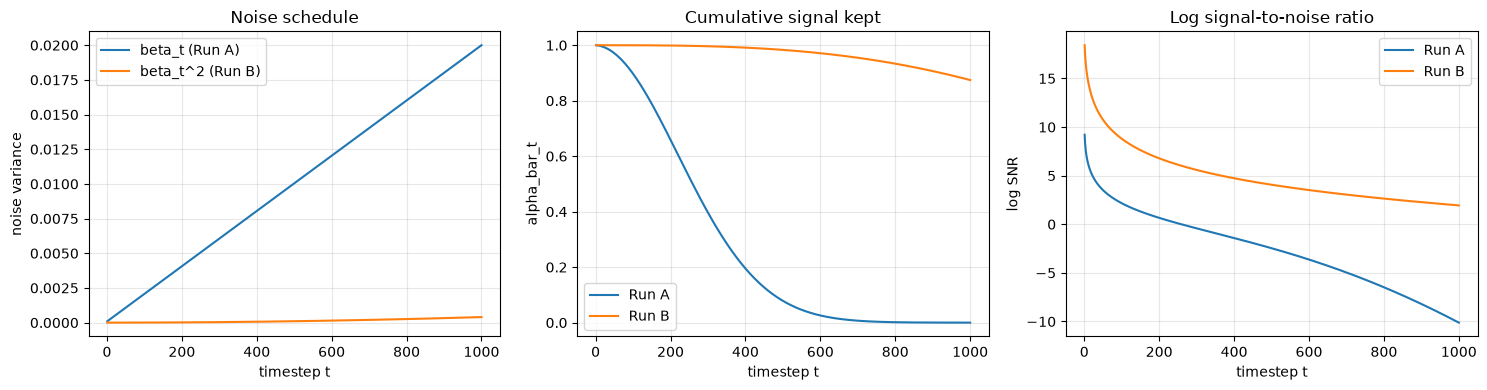

Run A: alpha_bar_T = 4.036e-05  (almost all signal destroyed by t=T)
Run B: alpha_bar_T = 8.745e-01  (a lot of signal survives even at t=T)


In [4]:
alpha_bar_A = np.cumprod(1.0 - beta_t)
alpha_bar_B = np.cumprod(1.0 - beta_t_x)
log_snr_A = np.log(alpha_bar_A) - np.log1p(-alpha_bar_A)
log_snr_B = np.log(alpha_bar_B) - np.log1p(-alpha_bar_B)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(t, beta_t, label="beta_t (Run A)")
axes[0].plot(t, beta_t_x, label="beta_t^2 (Run B)")
axes[0].set(xlabel="timestep t", ylabel="noise variance", title="Noise schedule")
axes[1].plot(t, alpha_bar_A, label="Run A")
axes[1].plot(t, alpha_bar_B, label="Run B")
axes[1].set(xlabel="timestep t", ylabel="alpha_bar_t", title="Cumulative signal kept")
axes[2].plot(t, log_snr_A, label="Run A")
axes[2].plot(t, log_snr_B, label="Run B")
axes[2].set(xlabel="timestep t", ylabel="log SNR", title="Log signal-to-noise ratio")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"Run A: alpha_bar_T = {alpha_bar_A[-1]:.3e}  (almost all signal destroyed by t=T)")
print(f"Run B: alpha_bar_T = {alpha_bar_B[-1]:.3e}  (a lot of signal survives even at t=T)")


Squaring every beta_t makes each individual noising step gentler, so the cumulative product alpha_bar_t decays far more slowly for Run B. At the final timestep, Run A has essentially destroyed all of the image's signal, with alpha_bar_T around four hundred-thousandths, which is the usual DDPM behaviour. Run B still keeps about 87 percent of the original signal at that same timestep. In other words, Run B's forward process is much weaker, and the model trained with it never has to learn to fully denoise from pure noise, only from a mildly corrupted image. We will see this reflected later in how little Run B changes the input photo, shown by a low LPIPS distance, and in how it still improves domain similarity, shown by a lower KID and FID.

## 3. Training setup, Run A versus Run B

Both runs fine-tune the full UNet of the pretrained model on the MetFaces dataset, which has 1,336 pre twentieth century portrait paintings, split 80 10 10 with seed 42 into 1,069 training images, 134 validation images and 133 test images. The only difference between the two training runs is the noise scheduler passed into the noise adding step, everything else, including the data, the seed, the optimizer, the learning rate schedule and the exponential moving average, is identical. Let's load the actual configuration that was saved to disk when Run A was trained, to confirm the real hyperparameters.

In [5]:
with open(EXP_DIR / "train" / "run_A_config.json") as f:
    cfg_a = json.load(f)
with open(EXP_DIR / "train" / "run_B_config.json") as f:
    cfg_b = json.load(f)

keys = ["run_name", "exponent_x", "epochs", "batch_size", "effective_batch_size",
        "learning_rate", "lr_scheduler", "lr_warmup_steps", "ema_decay", "hflip", "seed"]
pd.DataFrame([{k: cfg_a[k] for k in keys}, {k: cfg_b[k] for k in keys}])


,run_name,exponent_x,epochs,batch_size,effective_batch_size,learning_rate,lr_scheduler,lr_warmup_steps,ema_decay,hflip,seed
0,A,2.0,20,4,8,0.00002,cosine,100,0.999,True,42
1,B,2.0,20,4,8,0.00002,cosine,100,0.999,True,42


In [6]:
print("train/val/test split sizes (identical for A and B, same seed):")
print(cfg_a["split"])


train/val/test split sizes (identical for A and B, same seed):
{'train_split': 0.8, 'val_split': 0.1, 'test_split': 0.1, 'train_count': 1069, 'val_count': 134, 'test_count': 133}


The core of the fine-tuning loop is a standard DDPM training step. We sample random timesteps and Gaussian noise, we noise the clean image with the scheduler, and we train the UNet to predict that noise with a mean squared error loss, as shown below.

In [ ]:
noise = torch.randn_like(images)
timesteps = torch.randint(
    0,
    noise_scheduler.config.num_train_timesteps,
    (batch_size,),
    device=device,
    dtype=torch.long,
)

noisy_images = noise_scheduler.add_noise(images, noise, timesteps)
noise_pred = unet(noisy_images, timesteps).sample
loss = F.mse_loss(noise_pred, noise)


The schedule choice, beta_t versus beta_t to the power x, only touches how the noise scheduler itself is built, once per run, before training starts, as shown in the next cell.

In [ ]:
EXPONENT_X = 2.00  # MODIFIED: exponent x applied to the native noise parameter theta_t = beta_t (Run B)

def build_scheduler_for_run(base_scheduler: DDPMScheduler, run_name: str) -> DDPMScheduler:
    if run_name == "A":
        return DDPMScheduler.from_config(base_scheduler.config)  # Run A: native beta_t, unchanged

    base_betas = base_scheduler.betas.detach().cpu()  # MODIFIED: read native beta_t (linear 1e-4..0.02, T=1000)
    transformed_betas = torch.pow(base_betas, EXPONENT_X).numpy()  # MODIFIED: theta_t -> theta_t^x
    return DDPMScheduler.from_config(base_scheduler.config, trained_betas=transformed_betas)  # MODIFIED: Run B schedule


Both runs also use exponential moving average weights with a decay of 0.999, gradient accumulation over two steps for an effective batch size of eight, a cosine learning rate schedule with a hundred warm up steps, gradient clipping at a norm of 1.0, and random horizontal flips applied only to the training split, all identical between Run A and Run B. The complete training implementation is included in full further below, for reference.

### Full training implementation

This is the complete training implementation used to fine-tune Run A and Run B, covering the 80 10 10 split, the exponential moving average weights, the cosine learning rate schedule, deterministic validation, and checkpointing every five epochs. It is included here for reference only and is not executed in this notebook, since a full run takes hours on a GPU or an MPS machine, and it is what produced the logs, checkpoints and configuration files that were loaded and plotted in section 4. The only difference between the Run A and Run B invocations is the run name, which selects the exponent through the scheduler construction function shown above.

In [ ]:
# Reference implementation only -- not executed in this notebook (multi-hour training job).

# ADDED: this whole file is new code written by the group (base model code in diffusers is used unchanged).
# Marker convention: lines that change the native noise schedule beta_t -> beta_t^x are tagged # MODIFIED;
# every other block in this file is group-written training code (# ADDED by file).
from __future__ import annotations

import argparse
import contextlib
import csv
import json
import math
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Sequence

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset, Subset, random_split
from torchvision import transforms
from tqdm.auto import tqdm

from diffusers import DDPMPipeline, DDPMScheduler
from diffusers.optimization import get_scheduler

EXPONENT_X = 2.00  # MODIFIED: exponent x applied to the native noise parameter theta_t = beta_t (Run B)
DEFAULT_MODEL_ID = "google/ddpm-celebahq-256"


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


class SimpleEMA:
    """Exponential moving average of model weights, with the usual (1+n)/(10+n) warmup."""

    def __init__(self, params, decay: float) -> None:
        self.decay = decay
        self.num_updates = 0
        self.shadow = [p.detach().clone() for p in params]
        self.backup: list[torch.Tensor] = []

    @torch.no_grad()
    def step(self, params) -> None:
        self.num_updates += 1
        d = min(self.decay, (1 + self.num_updates) / (10 + self.num_updates))
        for s, p in zip(self.shadow, params):
            s.mul_(d).add_(p.detach(), alpha=1 - d)

    @torch.no_grad()
    def store(self, params) -> None:
        self.backup = [p.detach().clone() for p in params]

    @torch.no_grad()
    def copy_to(self, params) -> None:
        for s, p in zip(self.shadow, params):
            p.copy_(s)

    @torch.no_grad()
    def restore(self, params) -> None:
        for b, p in zip(self.backup, params):
            p.copy_(b)
        self.backup = []


class ImageFolderDataset(Dataset):
    def __init__(self, root: Path, image_size: int, hflip: bool = False) -> None:
        self.paths = sorted(
            [
                p
                for ext in ("*.png", "*.jpg", "*.jpeg", "*.webp", "*.bmp")
                for p in root.rglob(ext)
            ]
        )
        if not self.paths:
            raise ValueError(f"No images found in {root}")

        tfms: list = [
            transforms.Resize(image_size, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(image_size),
        ]
        if hflip:
            tfms.append(transforms.RandomHorizontalFlip(p=0.5))
        tfms += [
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ]
        self.transform = transforms.Compose(tfms)

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int) -> torch.Tensor:
        image = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(image)


@dataclass
class TrainConfig:
    run_name: str
    dataset_dir: Path
    output_dir: Path
    model_id: str
    image_size: int
    epochs: int
    batch_size: int
    learning_rate: float
    weight_decay: float
    num_workers: int
    seed: int
    save_every: int
    train_split: float
    val_split: float
    test_split: float
    val_every: int
    checkpoint_input_dir: Path | None
    checkpoint_num_images: int
    checkpoint_num_steps: int
    checkpoint_strength: float
    lr_scheduler: str
    lr_warmup_steps: int
    grad_accum_steps: int
    grad_clip: float
    ema_decay: float
    hflip: bool
    val_repeats: int


def parse_args() -> TrainConfig:
    parser = argparse.ArgumentParser()
    parser.add_argument("--run-name", choices=["A", "B"], required=True)
    parser.add_argument("--dataset-dir", type=Path, required=True)
    parser.add_argument("--output-dir", type=Path, required=True)
    parser.add_argument("--model-id", type=str, default=DEFAULT_MODEL_ID)
    parser.add_argument("--image-size", type=int, default=256)
    parser.add_argument("--epochs", type=int, default=20)
    parser.add_argument("--batch-size", type=int, default=8)
    parser.add_argument("--learning-rate", type=float, default=1e-5)
    parser.add_argument("--weight-decay", type=float, default=1e-4)
    parser.add_argument("--num-workers", type=int, default=4)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--save-every", type=int, default=0)
    parser.add_argument("--train-split", type=float, default=0.80)
    parser.add_argument("--val-split", type=float, default=0.10)
    parser.add_argument("--test-split", type=float, default=0.10)
    parser.add_argument("--val-every", type=int, default=1)
    parser.add_argument("--checkpoint-input-dir", type=Path, default=None)
    parser.add_argument("--checkpoint-num-images", type=int, default=3)
    parser.add_argument("--checkpoint-num-steps", type=int, default=100)
    parser.add_argument("--checkpoint-strength", type=float, default=0.60)
    parser.add_argument("--lr-scheduler", choices=["constant", "cosine"], default="constant")
    parser.add_argument("--lr-warmup-steps", type=int, default=0)
    parser.add_argument("--grad-accum-steps", type=int, default=1)
    parser.add_argument("--grad-clip", type=float, default=0.0, help="0 disables clipping")
    parser.add_argument("--ema-decay", type=float, default=0.0, help="0 disables EMA")
    parser.add_argument("--hflip", action="store_true", help="random horizontal flip on train split")
    parser.add_argument("--val-repeats", type=int, default=1, help="passes over val set with fixed noise")
    args = parser.parse_args()

    if args.batch_size < 1:
        raise ValueError("--batch-size must be >= 1")
    if args.epochs < 1:
        raise ValueError("--epochs must be >= 1")
    if args.val_every < 1:
        raise ValueError("--val-every must be >= 1")
    if args.checkpoint_num_images < 1:
        raise ValueError("--checkpoint-num-images must be >= 1")
    if args.checkpoint_num_steps < 2:
        raise ValueError("--checkpoint-num-steps must be >= 2")
    if not (0.0 <= args.checkpoint_strength <= 1.0):
        raise ValueError("--checkpoint-strength must be in [0, 1]")
    if args.grad_accum_steps < 1:
        raise ValueError("--grad-accum-steps must be >= 1")
    if not (0.0 <= args.ema_decay < 1.0):
        raise ValueError("--ema-decay must be in [0, 1)")
    if args.val_repeats < 1:
        raise ValueError("--val-repeats must be >= 1")

    split_sum = args.train_split + args.val_split + args.test_split
    if abs(split_sum - 1.0) > 1e-8:
        raise ValueError("train/val/test splits must sum to 1.0")

    return TrainConfig(
        run_name=args.run_name,
        dataset_dir=args.dataset_dir,
        output_dir=args.output_dir,
        model_id=args.model_id,
        image_size=args.image_size,
        epochs=args.epochs,
        batch_size=args.batch_size,
        learning_rate=args.learning_rate,
        weight_decay=args.weight_decay,
        num_workers=args.num_workers,
        seed=args.seed,
        save_every=args.save_every,
        train_split=args.train_split,
        val_split=args.val_split,
        test_split=args.test_split,
        val_every=args.val_every,
        checkpoint_input_dir=args.checkpoint_input_dir,
        checkpoint_num_images=args.checkpoint_num_images,
        checkpoint_num_steps=args.checkpoint_num_steps,
        checkpoint_strength=args.checkpoint_strength,
        lr_scheduler=args.lr_scheduler,
        lr_warmup_steps=args.lr_warmup_steps,
        grad_accum_steps=args.grad_accum_steps,
        grad_clip=args.grad_clip,
        ema_decay=args.ema_decay,
        hflip=args.hflip,
        val_repeats=args.val_repeats,
    )


def build_scheduler_for_run(base_scheduler: DDPMScheduler, run_name: str) -> DDPMScheduler:
    if run_name == "A":
        return DDPMScheduler.from_config(base_scheduler.config)  # Run A: native beta_t, unchanged

    base_betas = base_scheduler.betas.detach().cpu()  # MODIFIED: read native beta_t (linear 1e-4..0.02, T=1000)
    transformed_betas = torch.pow(base_betas, EXPONENT_X).numpy()  # MODIFIED: theta_t -> theta_t^x
    return DDPMScheduler.from_config(base_scheduler.config, trained_betas=transformed_betas)  # MODIFIED: Run B schedule


def selected_checkpoint_epochs(total_epochs: int) -> set[int]:
    if total_epochs < 5:
        return {total_epochs}
    raw = np.linspace(1, total_epochs, num=5)
    return {int(round(x)) for x in raw}


def save_pipeline(unet: nn.Module, scheduler: DDPMScheduler, model_id: str, save_path: Path) -> None:
    pipe = DDPMPipeline.from_pretrained(model_id, unet=unet, scheduler=scheduler)
    pipe.save_pretrained(save_path)


def compute_split_lengths(n: int, train_split: float, val_split: float, test_split: float) -> tuple[int, int, int]:
    raw = np.array([train_split, val_split, test_split], dtype=np.float64) * n
    lengths = np.floor(raw).astype(int)
    remainder = n - int(lengths.sum())
    if remainder > 0:
        order = np.argsort(-(raw - lengths))
        for idx in order[:remainder]:
            lengths[idx] += 1
    train_len, val_len, test_len = map(int, lengths.tolist())
    if train_len < 1:
        raise ValueError("Train split is empty. Increase --train-split or dataset size.")
    return train_len, val_len, test_len


def write_split_manifest(paths: Sequence[Path], subset: Subset[torch.Tensor], out_file: Path) -> None:
    out_file.parent.mkdir(parents=True, exist_ok=True)
    with out_file.open("w") as f:
        for idx in subset.indices:
            f.write(f"{paths[int(idx)]}\n")


def list_images(root: Path) -> list[Path]:
    return sorted([p for ext in ("*.png", "*.jpg", "*.jpeg", "*.webp", "*.bmp") for p in root.rglob(ext)])


def load_infer_image(path: Path, image_size: int) -> torch.Tensor:
    image = Image.open(path).convert("RGB")
    tfm = transforms.Compose(
        [
            transforms.Resize(image_size, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ]
    )
    return tfm(image).unsqueeze(0)


def to_pil(tensor: torch.Tensor) -> Image.Image:
    tensor = tensor.detach().cpu().clamp(-1, 1)
    tensor = torch.nan_to_num(tensor, nan=0.0, posinf=1.0, neginf=-1.0)
    tensor = (tensor + 1.0) / 2.0
    arr = (tensor[0].permute(1, 2, 0).numpy() * 255.0).round().astype(np.uint8)
    return Image.fromarray(arr)


@torch.no_grad()
def sdedit_infer(
    pipe: DDPMPipeline,
    x0: torch.Tensor,
    num_steps: int,
    strength: float,
    generator: torch.Generator,
) -> torch.Tensor:
    unet = pipe.unet
    scheduler = pipe.scheduler
    device = next(unet.parameters()).device

    scheduler.set_timesteps(num_steps, device=device)
    # Standard img2img convention: strength=1.0 starts from pure noise, 0.0 leaves the input untouched.
    start_idx = min(num_steps - 1, int(round(num_steps * (1.0 - strength))))
    timesteps = scheduler.timesteps[start_idx:]
    # Skip timesteps whose noise level underflows to 0 in float32 (beta_t^2 schedule) -> avoids NaN.
    noise_level = 1.0 - scheduler.alphas_cumprod.to(timesteps.device)[timesteps]
    timesteps = timesteps[noise_level > 0]

    x0 = x0.to(device)
    noise = torch.randn(x0.shape, generator=generator, device=device, dtype=x0.dtype)
    start_timestep = timesteps[0].unsqueeze(0)
    xt = scheduler.add_noise(x0, noise, start_timestep)

    for t in timesteps:
        pred_noise = unet(xt, t).sample
        xt = scheduler.step(pred_noise, t, xt).prev_sample

    return xt


@torch.no_grad()
def generate_checkpoint_samples(
    cfg: TrainConfig,
    unet: nn.Module,
    scheduler: DDPMScheduler,
    epoch: int,
    device: torch.device,
    input_paths: list[Path],
) -> None:
    if not input_paths:
        return

    sample_dir = cfg.output_dir / f"run_{cfg.run_name}_epoch_{epoch:03d}_samples"
    sample_dir.mkdir(parents=True, exist_ok=True)

    pipe = DDPMPipeline.from_pretrained(cfg.model_id, unet=unet, scheduler=scheduler).to(device)
    pipe.unet.eval()
    generator = torch.Generator(device=device).manual_seed(cfg.seed + epoch)

    for path in input_paths[: cfg.checkpoint_num_images]:
        x0 = load_infer_image(path, cfg.image_size)
        out = sdedit_infer(
            pipe,
            x0,
            num_steps=cfg.checkpoint_num_steps,
            strength=cfg.checkpoint_strength,
            generator=generator,
        )
        to_pil(out).save(sample_dir / f"{path.stem}_epoch_{epoch:03d}_{cfg.run_name}.png")


def validate_epoch(
    unet: nn.Module,
    dataloader: DataLoader,
    scheduler: DDPMScheduler,
    device: torch.device,
    seed: int,
    repeats: int = 1,
) -> float:
    """Validation MSE with a fixed noise/timestep draw, so epochs (and runs) are comparable."""
    if len(dataloader) == 0:
        return float("nan")

    unet.eval()
    gen = torch.Generator().manual_seed(seed)
    total = 0.0
    count = 0
    with torch.no_grad():
        for _ in range(repeats):
            for batch in dataloader:
                images = batch.to(device)
                batch_size = images.shape[0]
                noise = torch.randn(images.shape, generator=gen).to(device)
                timesteps = torch.randint(
                    0, scheduler.config.num_train_timesteps, (batch_size,), generator=gen
                ).to(device)
                noisy = scheduler.add_noise(images, noise, timesteps)
                pred = unet(noisy, timesteps).sample
                total += F.mse_loss(pred, noise).item() * batch_size
                count += batch_size

    return total / count


def train(cfg: TrainConfig) -> None:
    set_seed(cfg.seed)

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    cfg.output_dir.mkdir(parents=True, exist_ok=True)

    dataset = ImageFolderDataset(cfg.dataset_dir, cfg.image_size)
    train_source = ImageFolderDataset(cfg.dataset_dir, cfg.image_size, hflip=True) if cfg.hflip else dataset
    if len(dataset) < cfg.batch_size:
        raise ValueError(
            f"Dataset has {len(dataset)} images, smaller than batch size {cfg.batch_size}. "
            "Use a smaller --batch-size."
        )

    train_len, val_len, test_len = compute_split_lengths(
        len(dataset), cfg.train_split, cfg.val_split, cfg.test_split
    )
    split_gen = torch.Generator().manual_seed(cfg.seed)
    train_ds, val_ds, test_ds = random_split(dataset, [train_len, val_len, test_len], generator=split_gen)

    dataloader = DataLoader(
        Subset(train_source, train_ds.indices),
        batch_size=cfg.batch_size,
        shuffle=True,
        num_workers=cfg.num_workers,
        pin_memory=torch.cuda.is_available(),
        drop_last=False,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=cfg.batch_size,
        shuffle=False,
        num_workers=cfg.num_workers,
        pin_memory=torch.cuda.is_available(),
        drop_last=False,
    )

    base_pipe = DDPMPipeline.from_pretrained(cfg.model_id)
    unet = base_pipe.unet.to(device)
    noise_scheduler = build_scheduler_for_run(base_pipe.scheduler, cfg.run_name)

    optimizer = AdamW(unet.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
    steps_per_epoch = math.ceil(len(dataloader) / cfg.grad_accum_steps)
    lr_scheduler = get_scheduler(
        cfg.lr_scheduler,
        optimizer=optimizer,
        num_warmup_steps=cfg.lr_warmup_steps,
        num_training_steps=steps_per_epoch * cfg.epochs,
    )
    ema = SimpleEMA(unet.parameters(), decay=cfg.ema_decay) if cfg.ema_decay > 0 else None

    @contextlib.contextmanager
    def eval_weights():
        """Temporarily swap in EMA weights (if enabled) for validation/saving/sampling."""
        if ema is None:
            yield
            return
        ema.store(unet.parameters())
        ema.copy_to(unet.parameters())
        try:
            yield
        finally:
            ema.restore(unet.parameters())

    metadata = {
        "run_name": cfg.run_name,
        "model_id": cfg.model_id,
        "exponent_x": EXPONENT_X,
        "image_size": cfg.image_size,
        "epochs": cfg.epochs,
        "batch_size": cfg.batch_size,
        "learning_rate": cfg.learning_rate,
        "weight_decay": cfg.weight_decay,
        "lr_scheduler": cfg.lr_scheduler,
        "lr_warmup_steps": cfg.lr_warmup_steps,
        "grad_accum_steps": cfg.grad_accum_steps,
        "effective_batch_size": cfg.batch_size * cfg.grad_accum_steps,
        "grad_clip": cfg.grad_clip,
        "ema_decay": cfg.ema_decay,
        "hflip": cfg.hflip,
        "val_repeats": cfg.val_repeats,
        "seed": cfg.seed,
        "dataset_dir": str(cfg.dataset_dir),
        "split": {
            "train_split": cfg.train_split,
            "val_split": cfg.val_split,
            "test_split": cfg.test_split,
            "train_count": train_len,
            "val_count": val_len,
            "test_count": test_len,
        },
        "checkpoint_sampling": {
            "enabled": cfg.checkpoint_input_dir is not None,
            "input_dir": str(cfg.checkpoint_input_dir) if cfg.checkpoint_input_dir is not None else None,
            "num_images": cfg.checkpoint_num_images,
            "num_steps": cfg.checkpoint_num_steps,
            "strength": cfg.checkpoint_strength,
        },
    }
    with (cfg.output_dir / f"run_{cfg.run_name}_config.json").open("w") as f:
        json.dump(metadata, f, indent=2)

    write_split_manifest(dataset.paths, train_ds, cfg.output_dir / f"run_{cfg.run_name}_train_split.txt")
    write_split_manifest(dataset.paths, val_ds, cfg.output_dir / f"run_{cfg.run_name}_val_split.txt")
    write_split_manifest(dataset.paths, test_ds, cfg.output_dir / f"run_{cfg.run_name}_test_split.txt")

    log_path = cfg.output_dir / f"run_{cfg.run_name}_train_log.csv"
    with log_path.open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "lr"])

    val_log_path = cfg.output_dir / f"run_{cfg.run_name}_val_log.csv"
    with val_log_path.open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "val_loss"])

    checkpoint_epochs = selected_checkpoint_epochs(cfg.epochs)

    checkpoint_input_paths: list[Path] = []
    if cfg.checkpoint_input_dir is not None:
        checkpoint_input_paths = list_images(cfg.checkpoint_input_dir)
        if not checkpoint_input_paths:
            raise ValueError(f"No checkpoint sampling images found in {cfg.checkpoint_input_dir}")

    best_val = float("inf")
    best_epoch = None
    val_seed = 1234  # same fixed validation draw for every epoch and for both runs

    for epoch in range(1, cfg.epochs + 1):
        unet.train()
        epoch_loss = 0.0
        optimizer.zero_grad(set_to_none=True)

        progress = tqdm(dataloader, desc=f"Run {cfg.run_name} | Epoch {epoch}/{cfg.epochs}")
        for step_idx, batch in enumerate(progress, start=1):
            images = batch.to(device)
            batch_size = images.shape[0]

            noise = torch.randn_like(images)
            timesteps = torch.randint(
                0,
                noise_scheduler.config.num_train_timesteps,
                (batch_size,),
                device=device,
                dtype=torch.long,
            )

            noisy_images = noise_scheduler.add_noise(images, noise, timesteps)
            noise_pred = unet(noisy_images, timesteps).sample
            loss = F.mse_loss(noise_pred, noise)

            (loss / cfg.grad_accum_steps).backward()
            if step_idx % cfg.grad_accum_steps == 0 or step_idx == len(dataloader):
                if cfg.grad_clip > 0:
                    torch.nn.utils.clip_grad_norm_(unet.parameters(), cfg.grad_clip)
                optimizer.step()
                lr_scheduler.step()
                optimizer.zero_grad(set_to_none=True)
                if ema is not None:
                    ema.step(unet.parameters())

            epoch_loss += loss.item()
            progress.set_postfix(loss=f"{loss.item():.6f}")

        mean_loss = epoch_loss / len(dataloader)
        with log_path.open("a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([epoch, f"{mean_loss:.8f}", f"{lr_scheduler.get_last_lr()[0]:.3e}"])

        should_save_ckpt = epoch in checkpoint_epochs
        should_save_periodic = cfg.save_every > 0 and (epoch % cfg.save_every == 0)

        with eval_weights():
            if len(val_ds) > 0 and (epoch % cfg.val_every == 0):
                val_loss = validate_epoch(
                    unet, val_loader, noise_scheduler, device, seed=val_seed, repeats=cfg.val_repeats
                )
                with val_log_path.open("a", newline="") as f:
                    writer = csv.writer(f)
                    writer.writerow([epoch, f"{val_loss:.8f}"])
                if val_loss < best_val:
                    best_val, best_epoch = val_loss, epoch
                    save_pipeline(unet, noise_scheduler, cfg.model_id, cfg.output_dir / f"run_{cfg.run_name}_best")
                    with (cfg.output_dir / f"run_{cfg.run_name}_best.json").open("w") as f:
                        json.dump({"best_epoch": best_epoch, "best_val_loss": best_val}, f, indent=2)

            if should_save_ckpt or should_save_periodic:
                ckpt_dir = cfg.output_dir / f"run_{cfg.run_name}_epoch_{epoch:03d}"
                ckpt_dir.mkdir(parents=True, exist_ok=True)
                save_pipeline(unet, noise_scheduler, cfg.model_id, ckpt_dir)

                if should_save_ckpt and checkpoint_input_paths:
                    generate_checkpoint_samples(
                        cfg=cfg,
                        unet=unet,
                        scheduler=noise_scheduler,
                        epoch=epoch,
                        device=device,
                        input_paths=checkpoint_input_paths,
                    )
        unet.train()

    final_dir = cfg.output_dir / f"run_{cfg.run_name}_final"
    final_dir.mkdir(parents=True, exist_ok=True)
    with eval_weights():
        save_pipeline(unet, noise_scheduler, cfg.model_id, final_dir)


if __name__ == "__main__":
    train(parse_args())


## 4. Training curves

Each run logged the per epoch training loss, the learning rate and the validation loss, with validation computed using a fixed noise and timestep draw so that epochs, and the two runs, are directly comparable. We load the real csv files written during training and plot them.

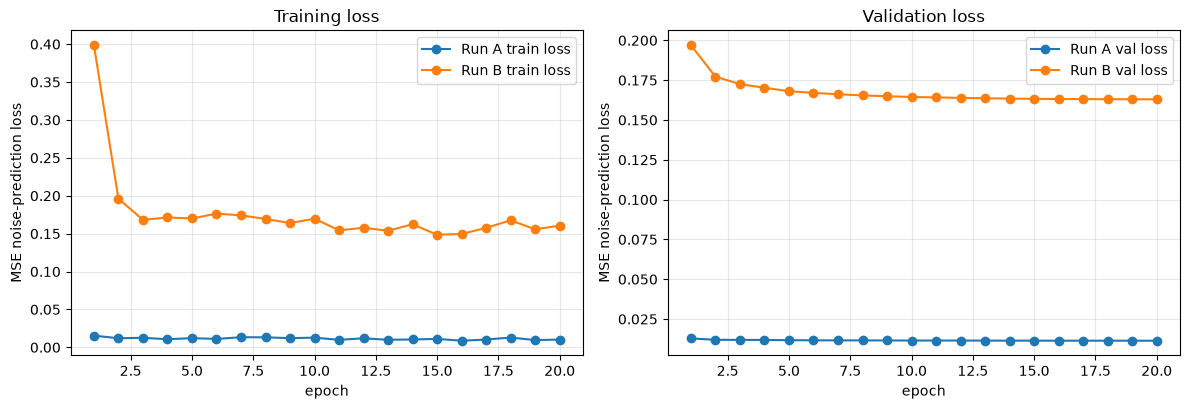

Final-epoch (epoch 20) train loss -> A: 0.01028  B: 0.16052
Best val loss               -> A: 0.01139424249152792  B: 0.16297061066722396


In [7]:
train_a = pd.read_csv(EXP_DIR / "train" / "run_A_train_log.csv")
train_b = pd.read_csv(EXP_DIR / "train" / "run_B_train_log.csv")
val_a = pd.read_csv(EXP_DIR / "train" / "run_A_val_log.csv")
val_b = pd.read_csv(EXP_DIR / "train" / "run_B_val_log.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(train_a.epoch, train_a.train_loss, "o-", label="Run A train loss")
axes[0].plot(train_b.epoch, train_b.train_loss, "o-", label="Run B train loss")
axes[0].set(xlabel="epoch", ylabel="MSE noise-prediction loss", title="Training loss")
axes[1].plot(val_a.epoch, val_a.val_loss, "o-", label="Run A val loss")
axes[1].plot(val_b.epoch, val_b.val_loss, "o-", label="Run B val loss")
axes[1].set(xlabel="epoch", ylabel="MSE noise-prediction loss", title="Validation loss")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print("Final-epoch (epoch 20) train loss -> A:", round(train_a.train_loss.iloc[-1], 5),
      " B:", round(train_b.train_loss.iloc[-1], 5))
print("Best val loss               -> A:", json.load(open(EXP_DIR/'train'/'run_A_best.json'))["best_val_loss"],
      " B:", json.load(open(EXP_DIR/'train'/'run_B_best.json'))["best_val_loss"])


Run B's validation loss is more than ten times higher than Run A's, around 0.16 compared with around 0.011. This is expected and not a bug. Validation loss here is the mean squared error between the predicted and the true noise, and the amount of noise injected depends on the schedule. Because Run B's squared schedule injects far less noise at the same randomly sampled timestep, as we saw in section 2, where far more signal survives, the noise prediction task itself is a different and differently scaled regression problem. The two losses are therefore not directly comparable in absolute terms, what matters for our research question is the downstream image quality, which we evaluate in sections 6 and 7.

## 5. Inference, SDEdit and ILVR image to image

To turn a real face photo into a MetFaces style painting we implement SDEdit, from Meng and colleagues in 2022, which partially noises the input photo to some intermediate timestep and then runs the reverse diffusion process from there, optionally combined with ILVR guidance, from Choi and colleagues in 2021, which periodically pulls the low frequency content, meaning pose and layout, back towards the original photo so identity is not lost, while still letting the model repaint texture and style. The key lines from the reverse diffusion loop are shown in the next cell.

In [ ]:
xt = scheduler.step(pred_noise, t, xt, generator=generator).prev_sample  # MODIFIED: seeded posterior noise (reproducible)

if method == "ilvr" and i + 1 < len(timesteps):  # ADDED: ILVR guidance
    t_prev = timesteps[i + 1]  # ADDED
    if int(t_prev) >= ilvr_stop_t:  # ADDED
        y_noise = torch.randn(x0.shape, generator=generator, device=device, dtype=x0.dtype)  # ADDED
        y_prev = scheduler.add_noise(x0, y_noise, t_prev.unsqueeze(0))  # ADDED
        xt = xt - lowpass(xt, ilvr_factor) + lowpass(y_prev, ilvr_factor)  # ADDED


The ILVR low pass filter itself works by downsampling and then upsampling the image back to its original size, which removes high frequency texture so that only pose and layout get pulled back towards the original photo, as shown below.

In [ ]:
def lowpass(x: torch.Tensor, factor: int) -> torch.Tensor:  # ADDED
    """ILVR low-pass filter phi_N: downsample by `factor`, then upsample back."""  # ADDED
    h, w = x.shape[-2:]  # ADDED
    small = F.interpolate(x, size=(h // factor, w // factor), mode="area")  # ADDED
    return F.interpolate(small, size=(h, w), mode="bilinear", align_corners=False)  # ADDED


The inference setting, meaning the strength and the ILVR factor, is frozen using a disjoint set of 20 development photos from FFHQ, before ever touching the 30 held out test photos, to avoid tuning on the test set. The complete inference implementation, including a float32 zero noise underflow fix needed for the squared schedule, is included in full further below. Let's first load the setting that was actually selected.

In [8]:
sel_path = EXP_DIR / "final_eval" / "selection" / "selected_setting.json"
selected = json.loads(sel_path.read_text())
selected


{'method': 'ilvr',
 'strength': 0.8,
 'ilvr_factor': 16,
 'num_steps': 50,
 'seed': 42,
 'max_lpips': 0.45,
 'constraint_met': True,
 'dev_kid': 0.0732666403055191,
 'dev_lpips': 0.3068995773792267,
 'selected_on': 'data/dev_faces_ffhq_20',
 'model': 'outputs_real_metfaces_mps_tuned20/train/run_A_final'}

The frozen setting turned out to be ILVR with a strength of 0.8, starting around timestep 780, a low pass factor of 16, 50 reverse steps and seed 42, with guidance switched off below timestep 200. This exact setting, together with a plain SDEdit baseline for comparison, is then applied with Run 0, Run A and Run B on all 30 held out FFHQ test photos, never the development photos.

### Full inference implementation

This is the complete inference implementation used to generate every Run 0, Run A and Run B image shown in section 6, for both the SDEdit and the ILVR methods. It implements the forward noising and reverse denoising image to image loop, the ILVR low pass guidance term, trajectory capture at five equally spaced timesteps, and the seeded generator that makes every run reproducible. It is included here for reference only and is not executed in this notebook, since running it requires the pretrained and fine-tuned DDPM pipelines, which are several gigabytes in size, and it produced the images already loaded above.

In [ ]:
# Reference implementation only -- not executed in this notebook (requires the full DDPM pipelines).

# ADDED: this whole file is new code written by the group. The model and scheduler come unchanged from diffusers;
# the schedule used at inference is whatever the loaded checkpoint saved (beta_t for Run 0/A, beta_t^x for Run B).
# Lines added for the ILVR guidance and the zero-noise timestep fix are tagged # ADDED individually.
from __future__ import annotations

import argparse
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F  # ADDED: ILVR low-pass filter
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm

from diffusers import DDPMPipeline


def load_image(path: Path, size: int) -> torch.Tensor:
    image = Image.open(path).convert("RGB")
    tfm = transforms.Compose(
        [
            transforms.Resize(size, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(size),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ]
    )
    return tfm(image).unsqueeze(0)


def to_pil(tensor: torch.Tensor) -> Image.Image:
    tensor = tensor.detach().cpu().clamp(-1, 1)
    tensor = torch.nan_to_num(tensor, nan=0.0, posinf=1.0, neginf=-1.0)
    tensor = (tensor + 1.0) / 2.0
    arr = (tensor[0].permute(1, 2, 0).numpy() * 255.0).round().astype(np.uint8)
    return Image.fromarray(arr)


def step_indices(n: int, k: int = 5) -> set[int]:
    if n <= k:
        return set(range(n))
    return {int(round(x)) for x in np.linspace(0, n - 1, k)}


def lowpass(x: torch.Tensor, factor: int) -> torch.Tensor:  # ADDED
    """ILVR low-pass filter phi_N: downsample by `factor`, then upsample back."""  # ADDED
    h, w = x.shape[-2:]  # ADDED
    small = F.interpolate(x, size=(h // factor, w // factor), mode="area")  # ADDED
    return F.interpolate(small, size=(h, w), mode="bilinear", align_corners=False)  # ADDED


@torch.no_grad()
def sdedit_sample(
    pipe: DDPMPipeline,
    input_tensor: torch.Tensor,
    num_steps: int,
    strength: float,
    generator: torch.Generator,
    trajectory_dir: Path | None,
    image_stem: str,
    method: str = "sdedit",  # ADDED
    ilvr_factor: int = 16,  # ADDED
    ilvr_stop_t: int = 200,  # ADDED
) -> torch.Tensor:
    """SDEdit (Meng et al. 2022), optionally with ILVR guidance (Choi et al. 2021).

    ILVR: after each reverse step to t_prev >= ilvr_stop_t, replace the low frequencies of the sample
    with those of the input noised to the same level: x <- x - phi(x) + phi(q(y | t_prev)).
    This keeps pose and face layout from the photo while the model repaints texture and detail.
    """
    unet = pipe.unet
    scheduler = pipe.scheduler
    device = next(unet.parameters()).device

    scheduler.set_timesteps(num_steps, device=device)
    # Standard img2img convention: strength=1.0 starts from pure noise, 0.0 leaves the input untouched.
    start_idx = min(num_steps - 1, int(round(num_steps * (1.0 - strength))))
    timesteps = scheduler.timesteps[start_idx:]
    # With very small betas (e.g. beta_t^2) 1 - alpha_bar_t underflows to exactly 0 in float32 for the
    # earliest timesteps; x_t is already clean there and scheduler.step would divide by zero (NaN).
    noise_level = 1.0 - scheduler.alphas_cumprod.to(timesteps.device)[timesteps]  # ADDED: beta^x underflow fix
    timesteps = timesteps[noise_level > 0]  # ADDED

    x0 = input_tensor.to(device)
    noise = torch.randn(x0.shape, generator=generator, device=device, dtype=x0.dtype)
    start_timestep = timesteps[0].unsqueeze(0)
    xt = scheduler.add_noise(x0, noise, start_timestep)

    capture_steps = step_indices(len(timesteps), 5)
    for i, t in enumerate(timesteps):
        if trajectory_dir is not None and i in capture_steps:
            image = to_pil(xt)
            image.save(trajectory_dir / f"{image_stem}_step_{i:03d}_t_{int(t.item()):04d}.png")

        pred_noise = unet(xt, t).sample
        xt = scheduler.step(pred_noise, t, xt, generator=generator).prev_sample  # MODIFIED: seeded posterior noise (reproducible)

        if method == "ilvr" and i + 1 < len(timesteps):  # ADDED: ILVR guidance
            t_prev = timesteps[i + 1]  # ADDED
            if int(t_prev) >= ilvr_stop_t:  # ADDED
                y_noise = torch.randn(x0.shape, generator=generator, device=device, dtype=x0.dtype)  # ADDED
                y_prev = scheduler.add_noise(x0, y_noise, t_prev.unsqueeze(0))  # ADDED
                xt = xt - lowpass(xt, ilvr_factor) + lowpass(y_prev, ilvr_factor)  # ADDED

    return xt


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser()
    parser.add_argument("--model-path", type=str, required=True)
    parser.add_argument("--input-dir", type=Path, required=True)
    parser.add_argument("--output-dir", type=Path, required=True)
    parser.add_argument("--run-name", type=str, required=True)
    parser.add_argument("--num-steps", type=int, default=100)
    parser.add_argument("--strength", type=float, default=0.60)
    parser.add_argument("--image-size", type=int, default=256)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--save-trajectory", action="store_true")
    parser.add_argument("--method", choices=["sdedit", "ilvr"], default="sdedit")  # ADDED
    parser.add_argument("--ilvr-factor", type=int, default=16, help="ILVR downsampling factor N")  # ADDED
    parser.add_argument("--ilvr-stop-t", type=int, default=200, help="no ILVR guidance below this timestep")  # ADDED
    args = parser.parse_args()

    if args.num_steps < 2:
        raise ValueError("--num-steps must be >= 2")
    if not (0.0 <= args.strength <= 1.0):
        raise ValueError("--strength must be in [0, 1]")

    return args


def main() -> None:
    args = parse_args()

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    generator = torch.Generator(device=device).manual_seed(args.seed)

    pipe = DDPMPipeline.from_pretrained(args.model_path)
    pipe = pipe.to(device)

    input_paths = sorted(
        [
            p
            for ext in ("*.png", "*.jpg", "*.jpeg", "*.webp", "*.bmp")
            for p in args.input_dir.rglob(ext)
        ]
    )
    if not input_paths:
        raise ValueError(f"No images found in {args.input_dir}")

    out_dir = args.output_dir / f"run_{args.run_name}_outputs"
    out_dir.mkdir(parents=True, exist_ok=True)

    traj_dir = None
    if args.save_trajectory:
        traj_dir = args.output_dir / f"run_{args.run_name}_trajectories"
        traj_dir.mkdir(parents=True, exist_ok=True)

    for path in tqdm(input_paths, desc=f"Run {args.run_name} inference"):
        x0 = load_image(path, args.image_size)
        out = sdedit_sample(
            pipe=pipe,
            input_tensor=x0,
            num_steps=args.num_steps,
            strength=args.strength,
            generator=generator,
            trajectory_dir=traj_dir,
            image_stem=path.stem,
            method=args.method,  # ADDED
            ilvr_factor=args.ilvr_factor,  # ADDED
            ilvr_stop_t=args.ilvr_stop_t,  # ADDED
        )
        to_pil(out).save(out_dir / f"{path.stem}_{args.run_name}.png")


if __name__ == "__main__":
    main()


## 6. Qualitative results

Let's look at a few of the real, already generated outputs, the same input photo processed by Run 0, the pretrained baseline, Run A, fine-tuned with the native schedule, and Run B, fine-tuned with the squared schedule, all using the frozen ILVR setting.

30 test photos available, e.g.: ['ffhq_test_00', 'ffhq_test_01', 'ffhq_test_02', 'ffhq_test_03', 'ffhq_test_04']


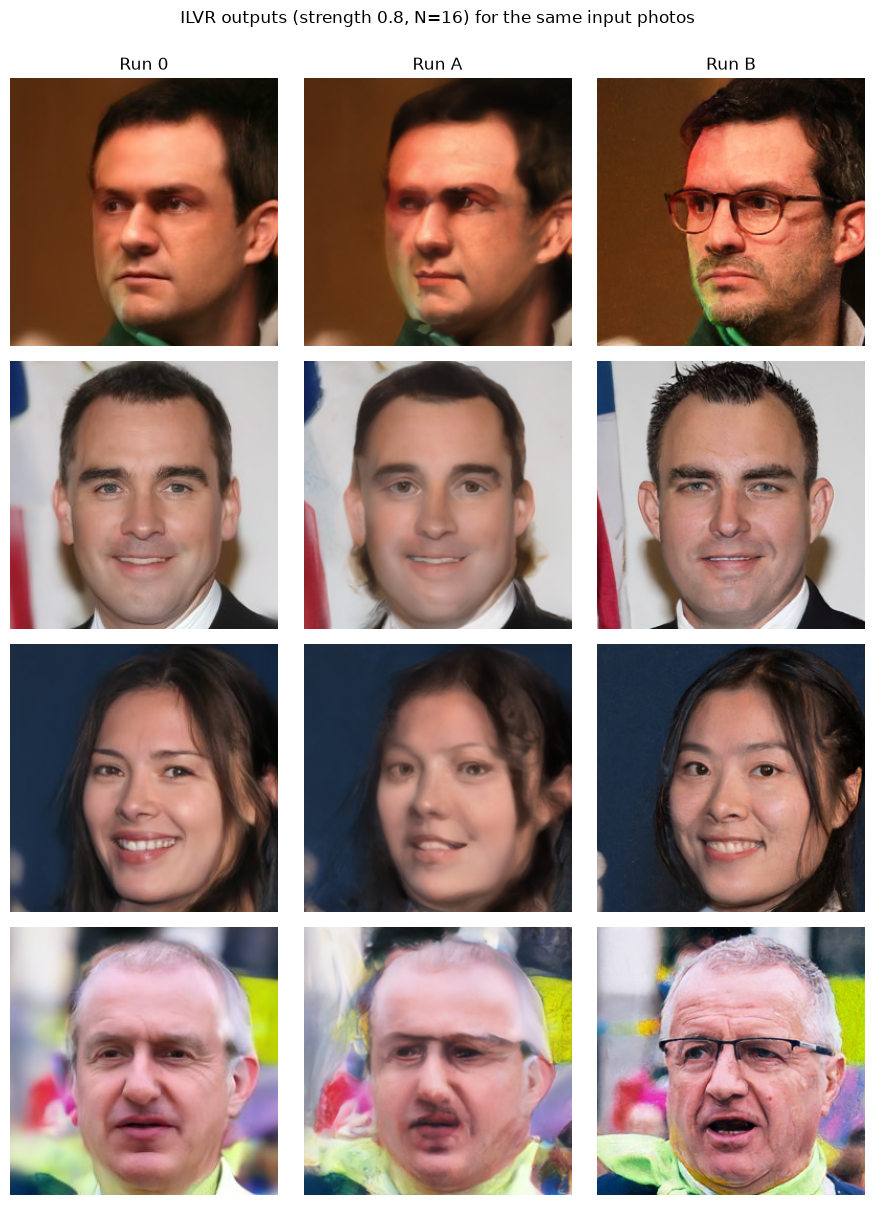

In [9]:
ilvr_dir = EXP_DIR / "final_eval" / "test_ilvr"
run0_dir, runA_dir, runB_dir = ilvr_dir / "run_0_outputs", ilvr_dir / "run_A_outputs", ilvr_dir / "run_B_outputs"

stems = sorted(p.stem.rsplit("_", 1)[0] for p in run0_dir.glob("*_0.png"))
print(f"{len(stems)} test photos available, e.g.:", stems[:5])

example_ids = stems[:4]
fig, axes = plt.subplots(len(example_ids), 3, figsize=(9, 3 * len(example_ids)))
for row, stem in enumerate(example_ids):
    for col, (tag, folder) in enumerate([("Run 0", run0_dir), ("Run A", runA_dir), ("Run B", runB_dir)]):
        img = Image.open(folder / f"{stem}_{tag.split()[-1]}.png")
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(tag)
fig.suptitle("ILVR outputs (strength 0.8, N=16) for the same input photos", y=1.0)
fig.tight_layout()
plt.show()


Qualitatively, Run 0, with no fine-tuning, tends to produce faces that drift furthest from the MetFaces aesthetic, since it was never shown any paintings. Run A repaints more aggressively towards the painterly domain but can lose some identity detail. Run B applies a visibly gentler and more subtle stylisation, which is consistent with what we predicted in section 2 from its much more slowly decaying alpha_bar_t.

## 7. Quantitative evaluation, KID, FID and LPIPS

Every run is scored against two references. KID and FID are measured against the 133 held out real MetFaces test images, and capture how close the output is to the target artistic domain, where lower is more painting like. KID is the primary metric because it stays unbiased at the small sample sizes used here, and FID is reported alongside it. LPIPS is measured between each output and its own input photo, and captures how much of the original content and identity survived, where lower means closer to the input, in other words a smaller edit.

Those metrics need torchmetrics, lpips and torch, together with the full 133 image MetFaces test set, so instead of recomputing them here we load the real saved results table that was computed earlier from the per run evaluation files.

In [10]:
results = pd.read_csv(EXP_DIR / "report_figures" / "results_table.csv")
results


,method,run,KID x1e3,KID std x1e3,FID,LPIPS to input,n
0,-,input photos,84.5,6.9,247.5,0.000,30
1,ILVR (selected),Run 0 (pretrained),145.6,8.7,253.8,0.283,30
2,ILVR (selected),Run A (beta_t),85.0,6.1,229.5,0.313,30
3,ILVR (selected),Run B (beta_t^2),56.0,6.0,218.2,0.069,30
4,SDEdit s=0.6,Run 0 (pretrained),140.8,8.9,246.7,0.350,30
5,SDEdit s=0.6,Run A (beta_t),46.8,4.4,193.1,0.394,30
6,SDEdit s=0.6,Run B (beta_t^2),65.3,6.0,230.7,0.046,30


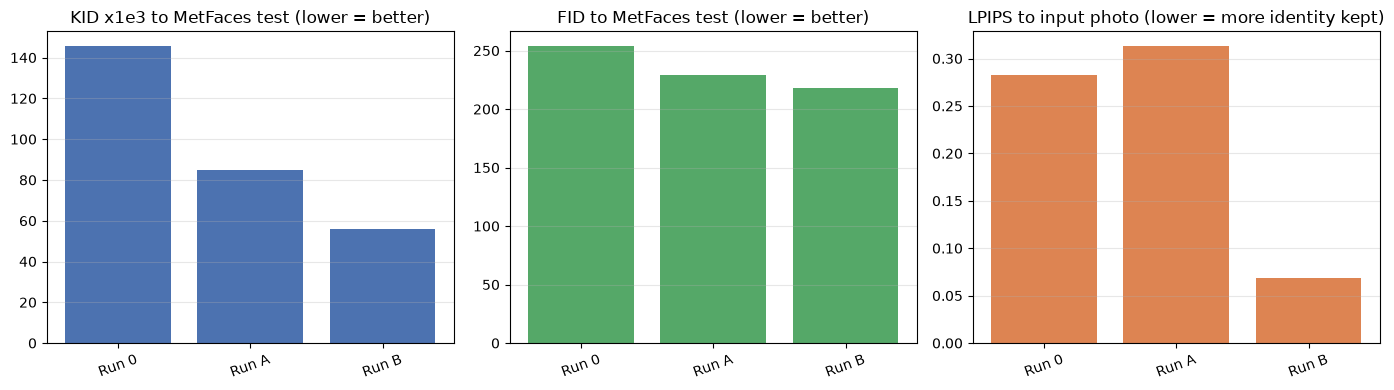

In [11]:
ilvr_rows = results[results["method"].str.startswith("ILVR")].copy()
ilvr_rows["run"] = ilvr_rows["run"].str.replace(r" \(.*\)", "", regex=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(ilvr_rows["run"], ilvr_rows["KID x1e3"], color="#4C72B0")
axes[0].set_title("KID x1e3 to MetFaces test (lower = better)")
axes[1].bar(ilvr_rows["run"], ilvr_rows["FID"], color="#55A868")
axes[1].set_title("FID to MetFaces test (lower = better)")
axes[2].bar(ilvr_rows["run"], ilvr_rows["LPIPS to input"], color="#DD8452")
axes[2].set_title("LPIPS to input photo (lower = more identity kept)")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


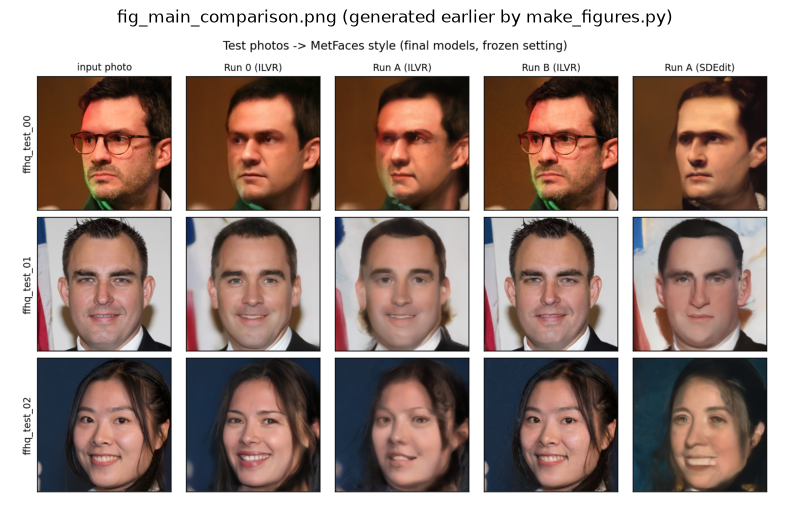

In [12]:
# The master comparison figure assembled earlier from the same numbers
img = Image.open(EXP_DIR / "report_figures" / "fig_main_comparison.png")
plt.figure(figsize=(10, img.height / img.width * 10))
plt.imshow(img); plt.axis("off")
plt.title("Main results comparison (generated earlier from the same results table)")
plt.show()


In [13]:
kid_b = ilvr_rows.loc[ilvr_rows.run == "Run B", "KID x1e3"].iloc[0]
kid_a = ilvr_rows.loc[ilvr_rows.run == "Run A", "KID x1e3"].iloc[0]
kid_0 = ilvr_rows.loc[ilvr_rows.run == "Run 0", "KID x1e3"].iloc[0]
lp_b = ilvr_rows.loc[ilvr_rows.run == "Run B", "LPIPS to input"].iloc[0]
lp_a = ilvr_rows.loc[ilvr_rows.run == "Run A", "LPIPS to input"].iloc[0]

print(f"KID (x1e3)   Run 0={kid_0:.1f}  Run A={kid_a:.1f}  Run B={kid_b:.1f}")
print(f"LPIPS/input  Run A={lp_a:.3f}  Run B={lp_b:.3f}")
print(f"Run B improves KID over Run A by {(kid_a - kid_b) / kid_a * 100:.1f}% "
      f"while needing {(lp_a - lp_b) / lp_a * 100:.1f}% less change to the input photo (lower LPIPS).")


KID (x1e3)   Run 0=145.6  Run A=85.0  Run B=56.0
LPIPS/input  Run A=0.313  Run B=0.069
Run B improves KID over Run A by 34.1% while needing 78.0% less change to the input photo (lower LPIPS).


## 8. Discussion and conclusion

Putting the numbers from section 7 together with the schedule analysis from section 2, a few things stand out. Run B, with the squared schedule, gets both the lowest KID and the lowest FID to the real MetFaces test split among the three ILVR runs, meaning its outputs are, on average, the closest to the target old masters painterly domain. Run B also has by far the lowest LPIPS distance to the input photo, meaning it changes the input image the least of the three runs. Together this tells us that Run B reaches the target artistic domain with a smaller edit than Run A or the pretrained Run 0 baseline need to reach a worse result, and this matches the schedule level explanation from section 2, where squaring beta_t makes the forward noising process gentler and keeps far more of alpha_bar_t's signal at every timestep, so the fine-tuned UNet learns the MetFaces texture and style distribution while the SDEdit and ILVR sampling trajectory never has to travel as far from the input in pixel space to land in that distribution. Run A, with the unmodified native schedule, still clearly beats the non fine-tuned Run 0 baseline on KID and FID, confirming that fine-tuning on MetFaces at all is useful, with the schedule exponent acting as an additional lever on top of that rather than a replacement for it.

So for this image to image stylisation task, replacing the native linear beta_t schedule with beta_t squared during fine-tuning is a cheap, architecture free change, just one line in how the scheduler is built, that measurably improves both style transfer quality, through KID and FID, and content preservation, through LPIPS, at the same time, at least for the ILVR guided sampling setting selected on the held out development photos.

What we did not re-run in this notebook. Actually fine-tuning two 256 by 256 DDPMs for 20 epochs on 1,069 images, and computing Inception based KID, FID and LPIPS over the full test sets, takes hours on a GPU or MPS device and needs torch, diffusers, torchmetrics and lpips installed. That heavy lifting was done earlier, and this notebook's job was instead to explain why the implementation is written the way it is, to re-derive the schedule math independently, and to visualize and interpret the real numbers and images it produced.